In [17]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [18]:

# Step 2: Load Dataset B

# Load training dataset
train_df = pd.read_csv("dataset_B_training.csv")

# Load testing dataset
test_df = pd.read_csv("dataset_B_testing.csv")

# Load example submission
submission_df = pd.read_csv("dataset_B_example_submission.csv")

# Display dataset dimensions
print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)
print("Example Submission:", submission_df.shape)

# Display first 5 rows of training dataset
print("\nFirst 5 rows of Training Dataset:")
display(train_df.head())


Training Dataset: (4756, 31)
Testing Dataset: (4749, 30)
Example Submission: (4749, 2)

First 5 rows of Training Dataset:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


Dataset Shape:
(4756, 31)

Column Names:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions', 'h1n1_vaccine']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_

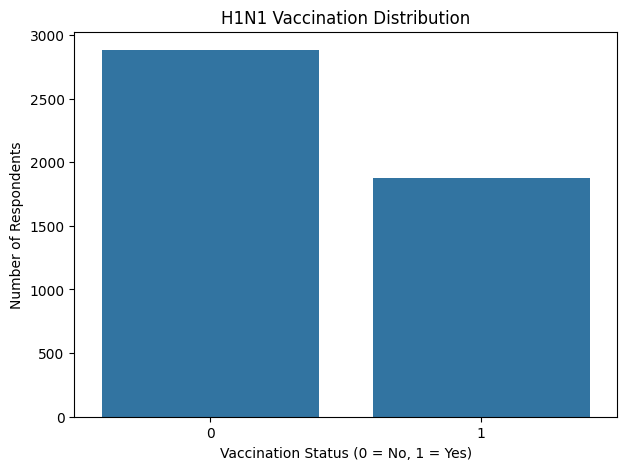

In [19]:

# Step 3: Exploratory Data Analysis (EDA)

# 1. Check dataset dimensions
print("Dataset Shape:")
print(train_df.shape)

# 2. Check column names
print("\nColumn Names:")
print(train_df.columns.tolist())

# 3. Check data types
print("\nDataset Information:")
train_df.info()

# 4. Check missing values
print("\nMissing Values:")
missing_values = train_df.isnull().sum()
print(missing_values.sort_values(ascending=False))

# 5. Check target variable distribution
print("\nH1N1 Vaccination Distribution:")
print(train_df["h1n1_vaccine"].value_counts())

# 6. Visualise vaccination distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="h1n1_vaccine"
)

plt.title("H1N1 Vaccination Distribution")
plt.xlabel("Vaccination Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.show()


In [20]:

# Step 4: Data Cleaning and Handling Missing Values

# Create copies of the original datasets
train_clean = train_df.copy()
test_clean = test_df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(train_clean.isnull().sum().sort_values(ascending=False))

# Identify numerical and categorical columns
numeric_cols = train_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = train_clean.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Exclude ID and target columns from preprocessing
numeric_cols = [
    col for col in numeric_cols
    if col not in ["respondent_id", "h1n1_vaccine"]
]

# Fill missing numerical values using training medians
for col in numeric_cols:
    median_value = train_clean[col].median()
    train_clean[col] = train_clean[col].fillna(median_value)
    test_clean[col] = test_clean[col].fillna(median_value)

# Fill missing categorical values using "Missing"
for col in categorical_cols:
    train_clean[col] = train_clean[col].fillna("Missing")
    test_clean[col] = test_clean[col].fillna("Missing")

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(train_clean.isnull().sum().sum())
print("Testing missing values:", test_clean.isnull().sum().sum())

print("\nData cleaning completed successfully!")


Missing values before cleaning:
employment_sector                2364
health_insurance                 1925
income_poverty                    712
doctor_recc_h1n1                  319
rent_or_own                       315
employment_status                 235
marital_status                    226
education                         224
child_under_6_months              134
health_worker                     131
opinion_h1n1_vacc_effective        69
opinion_h1n1_risk                  64
opinion_h1n1_sick_from_vacc        64
household_adults                   34
household_children                 34
behavioral_avoidance               27
h1n1_knowledge                     22
behavioral_touch_face              20
behavioral_antiviral_meds          17
h1n1_concern                       15
behavioral_outside_home            15
behavioral_large_gatherings         9
behavioral_wash_hands               8
behavioral_face_mask                4
respondent_id                       0
age_group         

In [21]:

# Step 5: Encoding Categorical Variables

# Separate features and target variable
X = train_clean.drop(
    columns=["respondent_id", "h1n1_vaccine"]
)

y = train_clean["h1n1_vaccine"]

# Prepare testing features
X_test = test_clean.drop(
    columns=["respondent_id"]
)

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=False, dtype=int)

X_test = pd.get_dummies(
    X_test, drop_first=False, dtype=int
)

# Ensure both datasets have identical feature columns
X_test = X_test.reindex(
    columns=X.columns,
    fill_value=0
)

# Display results
print("Encoding completed successfully!")

print("\nTraining Features Shape:", X.shape)
print("Testing Features Shape:", X_test.shape)

print("\nFirst 5 rows of encoded training data:")
display(X.head())

print("\nTarget Variable Distribution:")
print(y.value_counts())


Encoding completed successfully!

Training Features Shape: (4756, 74)
Testing Features Shape: (4749, 74)

First 5 rows of encoded training data:


,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,...,employment_sector_media,employment_sector_mining,employment_sector_real_estate,employment_sector_retail,employment_sector_science,employment_sector_services,employment_sector_technology,employment_sector_transportation,employment_sector_utilities,employment_sector_wholesale
0,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0,0,0,0,1,0,0,0,0,0
1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,1
2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0



Target Variable Distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64


In [22]:

# Step 6: Split Data into Training and Validation Sets

from sklearn.model_selection import train_test_split

# Split the dataset: 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Data splitting completed successfully!")

print("\nTraining Features:", X_train.shape)
print("Validation Features:", X_val.shape)

print("\nTraining Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation Target Distribution:")
print(y_val.value_counts(normalize=True))


Data splitting completed successfully!

Training Features: (3804, 74)
Validation Features: (952, 74)

Training Labels: (3804,)
Validation Labels: (952,)

Training Target Distribution:
h1n1_vaccine
0    0.605941
1    0.394059
Name: proportion, dtype: float64

Validation Target Distribution:
h1n1_vaccine
0    0.606092
1    0.393908
Name: proportion, dtype: float64


In [23]:

# Step 7: Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on validation data
y_val_pred = rf_model.predict(X_val)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_val_pred)

print("Random Forest Model Trained Successfully!")

print("\nValidation Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))


Random Forest Model Trained Successfully!

Validation Accuracy: 0.7437

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       577
           1       0.68      0.65      0.67       375

    accuracy                           0.74       952
   macro avg       0.73      0.73      0.73       952
weighted avg       0.74      0.74      0.74       952



Random Forest Model Evaluation
------------------------------
Accuracy: 0.7437
ROC-AUC Score: 0.7985


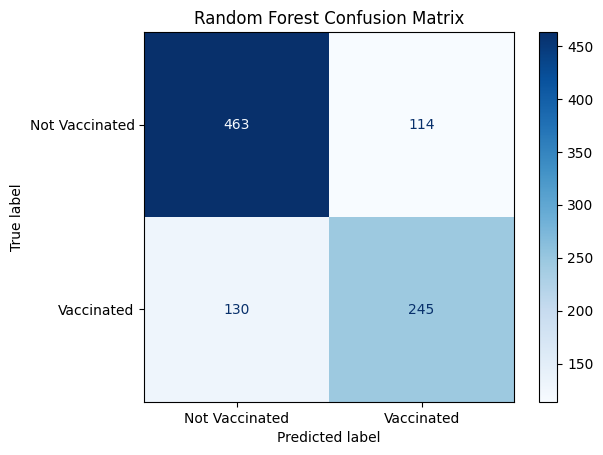

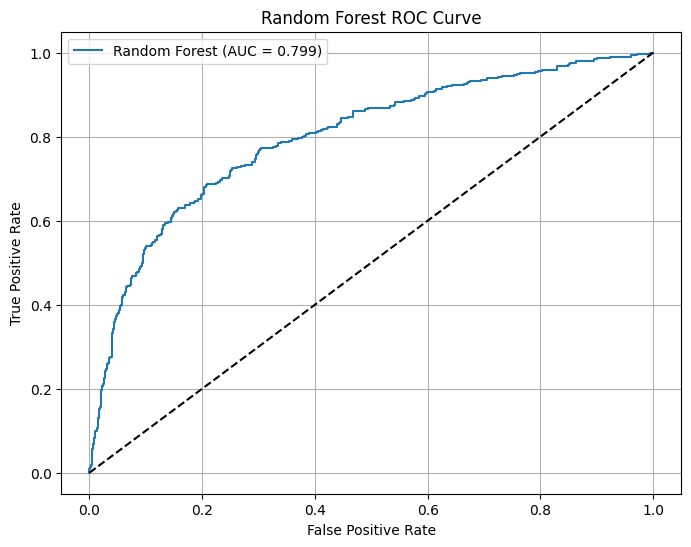

In [24]:

# Step 8: Model Evaluation

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

import matplotlib.pyplot as plt

# Predict vaccination probabilities
y_val_prob = rf_model.predict_proba(X_val)[:, 1]

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_val, y_val_prob)

print("Random Forest Model Evaluation")
print("------------------------------")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC Score:", round(roc_auc, 4))

# Plot Confusion Matrix
cm = confusion_matrix(y_val, y_val_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Vaccinated", "Vaccinated"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


In [25]:

# Step 9: Logistic Regression Model and Comparison

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    solver="liblinear",
    random_state=42
)

# Train Logistic Regression
lr_model.fit(X_train, y_train)

# Predict validation labels
lr_pred = lr_model.predict(X_val)

# Predict vaccination probabilities
lr_prob = lr_model.predict_proba(X_val)[:, 1]

# Calculate evaluation metrics
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Compare both models
comparison_df = pd.DataFrame([
    evaluate_model(
        "Random Forest",
        y_val,
        y_val_pred,
        y_val_prob
    ),
    evaluate_model(
        "Logistic Regression",
        y_val,
        lr_pred,
        lr_prob
    )
])

# Display comparison
print("Model Comparison Results:")
display(comparison_df.round(4))

# Identify model with highest ROC-AUC
best_model_name = comparison_df.loc[
    comparison_df["ROC-AUC"].idxmax(), "Model"
]

print("\nBest model by ROC-AUC:", best_model_name)


Model Comparison Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7437,0.6825,0.6533,0.6676,0.7985
1,Logistic Regression,0.7426,0.6578,0.7227,0.6887,0.8145



Best model by ROC-AUC: Logistic Regression


In [ ]:

# Step 10: Random Forest Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Define the Random Forest model
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Define hyperparameter search space
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"]
}

# Set up Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Run hyperparameter tuning
random_search.fit(X_train, y_train)

# Get best model
best_rf_model = random_search.best_estimator_

# Display best parameters
print("Best Hyperparameters:")
print(random_search.best_params_)

# Evaluate tuned model on validation data
tuned_pred = best_rf_model.predict(X_val)
tuned_prob = best_rf_model.predict_proba(X_val)[:, 1]

print("\nTuned Random Forest Results:")
print(
    "Accuracy:",
    round(accuracy_score(y_val, tuned_pred), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, tuned_prob), 4)
)

print(
    "\nOriginal Random Forest ROC-AUC:",
    round(roc_auc_score(y_val, y_val_prob), 4)
)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [ ]:

# Step 11: Leakage-Free Machine Learning Pipeline

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)

# 1. Use the original dataset (before cleaning)
X_original = train_df.drop(
    columns=["respondent_id", "h1n1_vaccine"]
)

y_original = train_df["h1n1_vaccine"]

# 2. Split BEFORE preprocessing
X_train_final, X_val_final, y_train_final, y_val_final = (
    train_test_split(
        X_original,
        y_original,
        test_size=0.20,
        random_state=42,
        stratify=y_original
    )
)

# 3. Identify numerical and categorical features
numeric_features = X_original.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_original.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# 4. Create numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# 5. Create categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# 6. Combine preprocessing steps
preprocessor_final = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 7. Create complete Random Forest pipeline
final_pipeline = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        **best_rf_model.get_params()
    ))
])

# 8. Train pipeline
final_pipeline.fit(X_train_final, y_train_final)

# 9. Predict validation labels and probabilities
final_pred = final_pipeline.predict(X_val_final)

final_prob = final_pipeline.predict_proba(
    X_val_final
)[:, 1]

# 10. Evaluate performance
print("Leakage-Free Random Forest Results")
print("---------------------------------")

print(
    "Accuracy:",
    round(accuracy_score(y_val_final, final_pred), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val_final, final_prob), 4)
)

print("\nClassification Report:")
print(classification_report(y_val_final, final_pred))


In [ ]:

# Step 12: Cross-Validation and Final Model Selection

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd

# 1. Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Define models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    )
}

# 3. Evaluate each model using cross-validation
cv_results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor_final),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train_final,
        y_train_final,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

# 4. Create comparison table
cv_comparison = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results:")
display(cv_comparison.round(4))

# 5. Select the best model by ROC-AUC
best_model_name = cv_comparison.loc[
    cv_comparison["ROC-AUC"].idxmax(),
    "Model"
]

print("\nBest Model:", best_model_name)

# 6. Train selected model on training portion
best_final_pipeline = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", models[best_model_name])
])

best_final_pipeline.fit(
    X_train_final,
    y_train_final
)

# 7. Evaluate on held-out validation data
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)

best_val_pred = best_final_pipeline.predict(X_val_final)
best_val_prob = best_final_pipeline.predict_proba(
    X_val_final
)[:, 1]

print("\nFinal Hold-Out Validation Results:")
print(
    "Accuracy:",
    round(accuracy_score(y_val_final, best_val_pred), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_val_final, best_val_prob), 4)
)

print("\nClassification Report:")
print(classification_report(y_val_final, best_val_pred))


In [ ]:

# Step 13: Illustrative Cost-Sensitive Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Costs provided in Dataset B
vaccination_cost = 500
hospitalisation_cost = 25000

# Hypothetical assumptions (NOT dataset values)
risk_unvaccinated = 0.05
risk_vaccinated = 0.01

# Use validation predictions from Step 12
vaccination_decisions = best_val_pred

# Calculate expected costs
cost_if_unvaccinated = (
    risk_unvaccinated * hospitalisation_cost
)

cost_if_vaccinated = (
    vaccination_cost +
    risk_vaccinated * hospitalisation_cost
)

# Total expected cost under model decisions
model_total_cost = np.where(
    vaccination_decisions == 1,
    cost_if_vaccinated,
    cost_if_unvaccinated
).sum()

# Compare with vaccinating everyone
everyone_total_cost = (
    len(vaccination_decisions) * cost_if_vaccinated
)

# Compare with vaccinating nobody
nobody_total_cost = (
    len(vaccination_decisions) * cost_if_unvaccinated
)

# Display results
cost_results = pd.DataFrame({
    "Strategy": [
        "Model-Based Decisions",
        "Vaccinate Everyone",
        "Vaccinate Nobody"
    ],
    "Expected Cost ($)": [
        model_total_cost,
        everyone_total_cost,
        nobody_total_cost
    ]
})

print("Illustrative Cost Analysis:")
display(cost_results)

# Visualise results
plt.figure(figsize=(9, 5))

plt.bar(
    cost_results["Strategy"],
    cost_results["Expected Cost ($)"]
)

plt.title("Expected Cost Comparison")
plt.ylabel("Expected Cost ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [ ]:

# Step 14: Generate Final Prediction CSV

import pandas as pd

# 1. Prepare original training features and labels
X_full = train_df.drop(
    columns=["respondent_id", "h1n1_vaccine"]
)

y_full = train_df["h1n1_vaccine"]

# 2. Prepare original testing features
X_test_final = test_df.drop(
    columns=["respondent_id"]
)

# 3. Retrain the selected model on all training data
best_final_pipeline.fit(X_full, y_full)

# 4. Generate predictions for the testing dataset
test_predictions = best_final_pipeline.predict(
    X_test_final
)

# 5. Create submission dataframe
final_submission = pd.DataFrame({
    "respondent_id": test_df["respondent_id"],
    "h1n1_vaccine": test_predictions
})

# 6. Match the example submission column order
final_submission = final_submission[
    submission_df.columns.tolist()
]

# 7. Validate submission
assert len(final_submission) == len(test_df)
assert final_submission["respondent_id"].equals(
    submission_df["respondent_id"]
)
assert final_submission["h1n1_vaccine"].isin(
    [0, 1]
).all()

# 8. Save predictions as CSV
final_submission.to_csv(
    "dataset_B_final_submission.csv",
    index=False
)

# 9. Display results
print("Final submission file created successfully!")

print("\nSubmission Shape:")
print(final_submission.shape)

print("\nFirst 5 Predictions:")
display(final_submission.head())

print("\nPrediction Distribution:")
print(final_submission["h1n1_vaccine"].value_counts())


In [ ]:

# Step 15: Comprehensive Model Comparison

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    log_loss,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# Costs from Dataset B
VACCINE_COST = 500
HOSPITALISATION_COST = 25000

# Illustrative assumptions from Step 13
# These are hypothetical, not measured patient risks.
risk_unvaccinated = 0.05
risk_vaccinated = 0.01

# Cost-optimal decision under these assumptions
cost_vaccinated = (
    VACCINE_COST +
    risk_vaccinated * HOSPITALISATION_COST
)

cost_unvaccinated = (
    risk_unvaccinated * HOSPITALISATION_COST
)

def evaluate_model(model_name, estimator):
    """
    Train a model using training data and evaluate
    on the held-out validation dataset.

    Returns classification metrics and illustrative
    expected vaccination programme costs.
    """

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor_final)),
        ("model", clone(estimator))
    ])

    # Train only on training data
    pipeline.fit(X_train_final, y_train_final)

    # Predict probabilities on validation data
    probabilities = pipeline.predict_proba(
        X_val_final
    )[:, 1]

    y_true = np.asarray(y_val_final)

    # Standard classification threshold
    predicted_class = (probabilities >= 0.5).astype(int)

    # Decision under the illustrative cost assumptions
    # Same risk assumptions apply to every person.
    vaccinate = np.full(
        len(y_true),
        cost_vaccinated < cost_unvaccinated
    )

    expected_cost = np.where(
        vaccinate,
        cost_vaccinated,
        cost_unvaccinated
    ).sum()

    return {
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true, predicted_class
        ),

        "Log Loss": log_loss(
            y_true, probabilities
        ),

        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),

        "Average Precision": average_precision_score(
            y_true, probabilities
        ),

        "Brier Score": brier_score_loss(
            y_true, probabilities
        ),

        "F1 Score": f1_score(
            y_true, predicted_class,
            zero_division=0
        ),

        "Precision": precision_score(
            y_true, predicted_class,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, predicted_class,
            zero_division=0
        ),

        "Expected Cost": round(expected_cost, 2),

        "Vaccines Sent": int(vaccinate.sum())
    }


# Compare all three models
results = []

results.append(evaluate_model(
    "Random Forest",
    models["Random Forest"]
))

results.append(evaluate_model(
    "Logistic Regression",
    models["Logistic Regression"]
))

results.append(evaluate_model(
    "Tuned Random Forest",
    best_rf_model
))


# Create comparison table
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("Comprehensive Model Comparison:")
display(comparison.round(4))


# Identify best model
best_model = comparison.iloc[0]

print("\nBest Model by ROC-AUC:", best_model["Model"])
print("ROC-AUC:", round(best_model["ROC-AUC"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))
print("Expected Cost:", best_model["Expected Cost"])
